In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity

from sentence_transformers import SentenceTransformer
import warnings
warnings.filterwarnings("ignore")

import gc
import torch


device = "cuda:1" if torch.cuda.is_available() else "cpu"
import gc


In [71]:
def data_processing(df, number_of_study, type_of_data):
    if number_of_study == 12:
        df = df.drop(columns=['Study3', 'Study7', 'Study9'])

        if type_of_data == "cleaned_version2":
            sheet_name = "twodecnefcond_cleaned_version2"
        elif type_of_data == "cleaned_version1":
            sheet_name = "twodecnefcond_cleaned_version1"
        else:
            sheet_name = "twodecnefcond_rawdata"

        df_high_low = pd.read_excel("verbal_reports.xlsx", sheet_name=sheet_name)
        df = pd.concat([df, df_high_low], axis=1)

        target_sentences = ["Feared animal", "Grating orientation", "High face preference", "Low face preference",
                            "Dog", "Red and high confidence", "Red", "High pain", "Low pain",
                            "Red and green", "High confidence", "Low confidence"]
        target_to_label = {t: i for i, t in enumerate(target_sentences)}

        # !!! high-low sheet'indeki GERÇEK sütun adlarını yaz (aşağıdakiler tahmin)
        col_to_target = {
            "Study1": "Feared animal",
            "Study2": "Grating orientation",
            "Study4": "Dog",
            "Study5": "Red and high confidence",
            "Study6": "Red",
            "Study8": "Red and green",
            "Study3HighPreference": "High face preference",
            "Study3LowPreference":  "Low face preference",
            "Study7HighPain": "High pain",
            "Study7LowPain":  "Low pain",
            "Study9HighConfidence": "High confidence",
            "Study9LowConfidence":  "Low confidence",
        }

    elif number_of_study == 6:
        df = df.drop(columns=['Study3', 'Study7', 'Study9'])
        target_sentences = ["Feared animal", "Grating orientation", "Dog",
                            "Red and high confidence", "Red", "Red and green"]
        target_to_label = {t: i for i, t in enumerate(target_sentences)}
        col_to_target = {
            "Study1": "Feared animal",
            "Study2": "Grating orientation",
            "Study4": "Dog",
            "Study5": "Red and high confidence",
            "Study6": "Red",
            "Study8": "Red and green",
        }

       
    elif number_of_study == 9:
        target_sentences = ["Feared animal", "Grating orientation", "Face preference", "Dog",
                            "Red and high confidence", "Red", "Pain", "Red and green", "Confidence"]
        target_to_label = {t: i for i, t in enumerate(target_sentences)}
        col_to_target = {
            "Study1": "Feared animal",
            "Study2": "Grating orientation",
            "Study3": "Face preference",
            "Study4": "Dog",
            "Study5": "Red and high confidence",
            "Study6": "Red",
            "Study7": "Pain",
            "Study8": "Red and green",
            "Study9": "Confidence",
        }

   


    study_cols = [col for col in df.columns if col in col_to_target]
    
    missing = set(col_to_target) - set(df.columns)
    assert not missing, f"Columns not found in sheet: {missing}"
    
    df = df.melt(value_vars=study_cols, var_name="study", value_name="text")
    df["label"] = df["study"].map(col_to_target).map(target_to_label)

    df = df.dropna(subset=["text"]).reset_index(drop=True)

    print("data frame final shape", df.shape)
    print(df["study"].unique(), df["label"].unique())

    return df, target_to_label, target_sentences

In [72]:
type_of_data="cleaned_version1"
number_of_study= 9
df, target_to_label, target_sentences=data_processing(pd.read_excel("verbal_reports.xlsx",sheet_name=f"{type_of_data}"),number_of_study,type_of_data)



data frame final shape (127, 3)
['Study1' 'Study2' 'Study3' 'Study4' 'Study5' 'Study6' 'Study7' 'Study8'
 'Study9'] [0 1 2 3 4 5 6 7 8]


In [73]:
df

,study,text,label
0,Study1,make the circle in 3D in mind. Concentrate on ...,0
1,Study1,Imagining arrows shooting at the center of the...,0
2,Study1,"Imagining songs, petting a cat, various sport ...",0
3,Study1,Concentrate on the green circle and try to thi...,0
4,Study1,"Imagining singing a song in head, driving a ca...",0
...,...,...,...
122,Study9,"Gaze and focus at the screen, look carefully f...",8
123,Study9,"Random thoughts, thinking about part-time job....",8
124,Study9,Concentrate on the induction cue (green circle...,8
125,Study9,"Thinking about the graduation thesis. Cooking,...",8


In [74]:
models_to_try = [
    
    "stsb-roberta-large",
    "all-mpnet-base-v2",
    "sentence-t5-xl",
    "gtr-t5-large",
    "all-roberta-large-v1",
    'sentence-t5-xxl',
    'gtr-t5-xxl',
    "all-mpnet-base-v1",
    "all-MiniLM-L6-v2",
    "all-MiniLM-L12-v1",
    "multi-qa-mpnet-base-dot-v1"

]

In [75]:

# Dictionary to store sim_matrix for each model
sim_matrices = {}

# ============================
# 1) Compute similarity matrices for each model
# ============================
for model_name in models_to_try:
    print(f"--- Model: {model_name} ---")

    model = SentenceTransformer(model_name, device=device)

    # Compute embeddings
    embeddings = model.encode(df["text"].tolist(), convert_to_numpy=True, show_progress_bar=False)
    target_embeddings = model.encode(target_sentences, convert_to_numpy=True, show_progress_bar=False)
    print("target embedding shape: ",target_embeddings.shape, "sentence embedding shape:", embeddings.shape)

    # Cosine similarity matrix
    sim_matrix = cosine_similarity(target_embeddings, embeddings)

    # SAVE IT IN DICTIONARY
    sim_matrices[model_name] = sim_matrix
  
  
    del model
    del embeddings
    del target_embeddings
    torch.cuda.empty_cache()  
    gc.collect()              

--- Model: stsb-roberta-large ---
target embedding shape:  (9, 1024) sentence embedding shape: (127, 1024)
--- Model: all-mpnet-base-v2 ---
target embedding shape:  (9, 768) sentence embedding shape: (127, 768)
--- Model: sentence-t5-xl ---
target embedding shape:  (9, 768) sentence embedding shape: (127, 768)
--- Model: gtr-t5-large ---
target embedding shape:  (9, 768) sentence embedding shape: (127, 768)
--- Model: all-roberta-large-v1 ---
target embedding shape:  (9, 1024) sentence embedding shape: (127, 1024)
--- Model: sentence-t5-xxl ---
target embedding shape:  (9, 768) sentence embedding shape: (127, 768)
--- Model: gtr-t5-xxl ---
target embedding shape:  (9, 768) sentence embedding shape: (127, 768)
--- Model: all-mpnet-base-v1 ---
target embedding shape:  (9, 768) sentence embedding shape: (127, 768)
--- Model: all-MiniLM-L6-v2 ---
target embedding shape:  (9, 384) sentence embedding shape: (127, 384)
--- Model: all-MiniLM-L12-v1 ---
target embedding shape:  (9, 384) sentenc

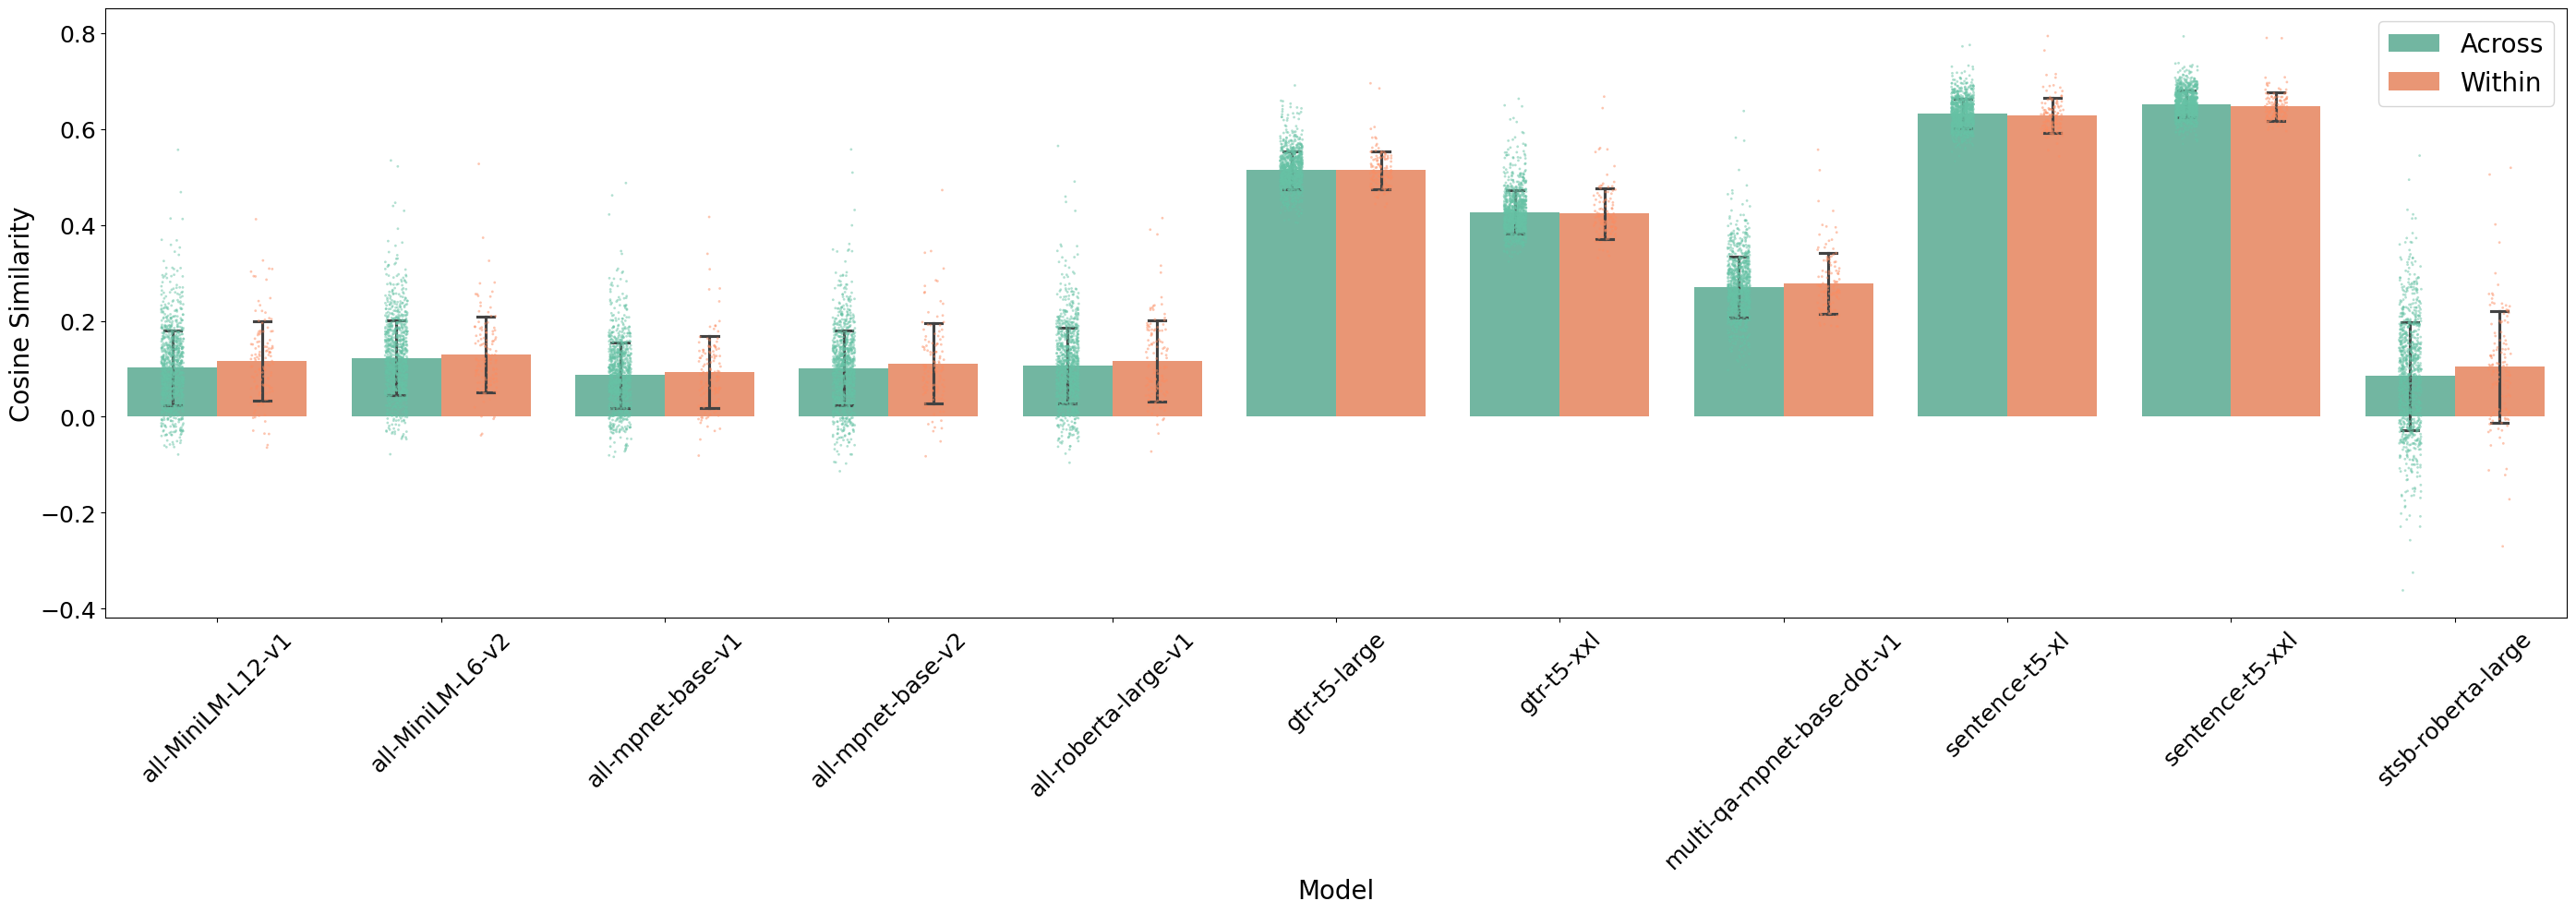

In [76]:
# ============================
# Extract Within / Across correlations for all models (vectorized)
# ============================
col_labels = df["label"].to_numpy()
target_ids = np.array([target_to_label[t] for t in target_sentences])
target_arr = np.asarray(target_sentences)

# Boolean mask: True where the target's label matches the column's label
within_mask = target_ids[:, None] == col_labels[None, :]
type_flat = np.where(within_mask, "Within", "Across").ravel()
sentence_flat = np.repeat(target_arr, len(col_labels))

frames = [
    pd.DataFrame({
        "Model": model_name,
        "Type": type_flat,
        "Correlation": np.asarray(sim_matrix).ravel(),
        "Sentence": sentence_flat,
    })
    for model_name, sim_matrix in sim_matrices.items()
]

df_all = pd.concat(frames, ignore_index=True)
df_all["Type"] = df_all["Type"].astype("category")
df_all["Model"] = df_all["Model"].astype("category")

# ============================
# Per-model Within/Across means
# ============================
mean_df = df_all.groupby(["Model", "Type"], observed=True)["Correlation"].mean().reset_index()


# ============================
# Plot
# ============================
plt.figure(figsize=(28, 10))

sns.barplot(
    data=df_all,
    x="Model",
    y="Correlation",
    hue="Type",
    ci="sd",
    capsize=0.15,
    palette="Set2"
)

sns.stripplot(
    data=df_all,
    x="Model",
    y="Correlation",
    hue="Type",
    dodge=True,
    size=2,
    alpha=0.5,
    palette="Set2"
)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], fontsize=20)

plt.xlabel("Model",fontsize=20)
plt.ylabel("Cosine Similarity", fontsize=20)
plt.yticks(fontsize=18)
plt.xticks(rotation=45, fontsize=18)
plt.tight_layout()
plt.show()



In [77]:
# Pivot the dataframe to wide format

wide_df = mean_df.pivot(index="Model", columns="Type", values="Correlation").reset_index()
print(wide_df)

#wide_df.to_csv(f"{type_of_data}_{number_of_study}.csv", index=False)



Type                       Model    Across    Within
0              all-MiniLM-L12-v1  0.102584  0.116622
1               all-MiniLM-L6-v2  0.122954  0.130395
2              all-mpnet-base-v1  0.086761  0.092687
3              all-mpnet-base-v2  0.101081  0.111253
4           all-roberta-large-v1  0.107159  0.116705
5                   gtr-t5-large  0.514159  0.514446
6                     gtr-t5-xxl  0.427065  0.423818
7     multi-qa-mpnet-base-dot-v1  0.270274  0.278111
8                 sentence-t5-xl  0.632498  0.627755
9                sentence-t5-xxl  0.652434  0.647223
10            stsb-roberta-large  0.085066  0.104691
